
# DSAF-Net: A Dual-Stream Attention-Fused Hybrid Network for Medulloblastoma Histopathology Subtyping

**Task.** Classify histopathology images of medulloblastoma into WHO histological subtypes
(Classic, Desmoplastic/Nodular, Extensive Nodularity, Large-Cell/Anaplastic), with an optional
"Non-Tumor" class if your dataset includes normal tissue for a detection setting.

**Why this architecture.** The published pipelines surveyed for this project fall into two
families: (a) feature-fusion approaches that combine deep CNN embeddings with handcrafted
texture descriptors and classical classifiers (Attallah & Zaghlool, 2022; Attallah, 2021), and
(b) end-to-end transfer-learning ensembles of pretrained CNNs (Bhuma & Kongara, 2020; Sathwik et
al., 2024), with a smaller line of work exploring Vision Transformers and stain normalization
(Belaskri et al., 2024) or bio-inspired optimizers and texture-heavy preprocessing
(Ramaswamy et al., 2023, 2025). None of the histopathology pipelines used a channel/spatial
attention block for interpretability, and several relied on ensembles of 3-10 CNNs, which does
not fit a single 6 GB consumer GPU.

DSAF-Net borrows the *idea* of feature fusion from Attallah's work but replaces the classical
ML back-end (LDA/QDA/SVM ensembles) with a single trainable dual-stream network, and replaces
plain global pooling with a CBAM attention block so that Grad-CAM has a sharper, more clinically
legible activation map to explain. It keeps the compute budget of one backbone rather than ten:

- **Deep stream:** a pretrained CNN backbone (EfficientNetV2-S by default) + CBAM attention
  + global average pooling.
- **Handcrafted stream:** GLCM (gray-level co-occurrence matrix) and LBP (local binary pattern)
  texture descriptors, the same family of features used by Attallah's textural images, but kept
  as compact feature vectors rather than full secondary images, so they can be computed in
  milliseconds at inference time.
- **Fusion head:** concatenation of both streams followed by a small MLP classifier.
- **Optional extension:** a second lightweight backbone (MobileNetV3-Small) trained
  independently and soft-voted with the primary model, as a scaled-down nod to the CNN-ensemble
  papers above — off by default, toggle with `USE_ENSEMBLE_EXTENSION`.

**Explainability.** Grad-CAM and Grad-CAM++ on the deep stream's last convolutional block,
plus a permutation-importance readout for the handcrafted texture features.

**Deployment.** A Gradio app in the final section: the user uploads a histopathology image,
the notebook runs the full preprocessing pipeline, returns the predicted subtype with
confidence, and overlays the Grad-CAM heatmap. The same cell exports a `SavedModel` and a
TFLite model for use outside the notebook (e.g. a Flask API or mobile app).

**Honest scope note.** This notebook is a research/teaching pipeline, not a validated clinical
tool. Limitations are called out inline wherever they matter (dataset leakage risk, sample size,
single-institution bias, patch- vs. slide-level inference) rather than glossed over.


## 1. Environment & Imports

In [1]:

# Tested against TensorFlow 2.9.1 in a conda env (matches the local RTX 3060 / tf_gpu setup).
# If you're on Colab, TensorFlow will already be newer; the code below does not use any
# 2.9-specific API so it should run unchanged on newer TF versions too.

import os, json, random, re, glob, math, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks

from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedKFold
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                              ConfusionMatrixDisplay, f1_score)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.inspection import permutation_importance

from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for g in gpus:
            tf.config.experimental.set_memory_growth(g, True)
        print(f"Found {len(gpus)} GPU(s), memory growth enabled:", gpus)
    except RuntimeError as e:
        print(e)
else:
    print("No GPU found - running on CPU. Training will be slow; consider Colab (T4) for the full run.")

print("TensorFlow:", tf.__version__)


Found 1 GPU(s), memory growth enabled: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow: 2.9.1



### Environment note: SSL fix + ConvNeXt-Tiny via TF-Hub (TF 2.9.1 workaround)

`tf.keras.applications.ConvNeXtTiny` only ships from TF 2.10 onward; this environment runs TF
2.9.1 (per the local `tf_gpu` conda setup), so `BACKBONE_NAME = "ConvNeXtTiny"` in Section 7 is
served from an ImageNet-pretrained TF-Hub SavedModel instead
(`sayakpaul/convnext_tiny_1k_224_fe`) — no PyTorch, no repo clone. The `certifi`-backed SSL
context below avoids the certificate errors Windows sometimes throws when Keras/TF-Hub download
pretrained weights, same fix as the tomato-leaf-disease notebooks. `tensorflow-hub` is pinned and
installed with `--no-deps` so pip can't touch the existing TF/numpy/protobuf install.


In [2]:

import ssl, certifi, sys

def _certifi_https_context(purpose=ssl.Purpose.SERVER_AUTH, cafile=None, capath=None, cadata=None):
    context = ssl.SSLContext(ssl.PROTOCOL_TLS_CLIENT)
    context.verify_mode = ssl.CERT_REQUIRED
    context.check_hostname = True
    context.load_verify_locations(cafile=certifi.where())
    return context

ssl._create_default_https_context = _certifi_https_context

try:
    import tensorflow_hub as hub  # noqa: F401
    print("tensorflow-hub already installed")
except ImportError:
    print("Installing tensorflow-hub ...")
    os.system(f'"{sys.executable}" -m pip install -q tensorflow-hub==0.12.0 --no-deps')
    import tensorflow_hub as hub  # noqa: F401
    print("tensorflow-hub installed")


tensorflow-hub already installed



## 2. Configuration

Set up for the GMCH medulloblastoma histopathology dataset (`database.xlsx` + `final_database/`),
where images are organized by **magnification**, not by class:

```
final_database/
    10x/
        411 (1).jpg ... 411 (25).jpg      # slide 411/16 -> Desmoplastic
        321 (1).jpg ... 321 (30).jpg      # slide 321/6  -> Classic
        N (1).jpg   ... N (50).jpg        # normal tissue
        ...
    100x/
        (same slides, second magnification)
```

The slide/self-id -> subtype mapping below was transcribed from `database.xlsx`'s `10x`/`100x`/
`Total` sheets; six slides with ambiguous or non-medulloblastoma diagnoses ("bad slide",
pilocytic astrocytoma, etc.) are excluded. See Section 3 for how filenames are matched back to
this table.


In [3]:

# ---- paths -----------------------------------------------------------------
DATA_DIR = r"C:\Users\Shafique\Documents\uni\healthcare project\final_database"
OUTPUT_DIR = "./outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Dataset is organized by MAGNIFICATION, not by class:
#   final_database/10x/*.jpg, final_database/100x/*.jpg
# Filenames encode the slide/self-id, e.g. "411 (8).jpg", "17126 (1).jpg", "N (3).jpg".
MAGNIFICATION_DIRS = ["10x", "100x"]   # set to a single-element list, e.g. ["100x"], to train on one magnification only

# ---- classes -----------------------------------------------------------------
# Merges "Desmoplastic" and "Nodular" into WHO's combined "Desmoplastic/Nodular" subtype.
# Also because the raw dataset has only 1 slide labeled "Nodular" alone - a single patient
# can't be split across train/val/test without leakage, so a class built from one patient
# isn't evaluable in isolation. Set to False only if you accept that "Nodular" will then
# have zero group-level evaluation signal.
MERGE_DESMOPLASTIC_NODULAR = True

CLASS_NAMES = (
    ["Classic", "Desmoplastic_Nodular", "Largecell", "Normal"] if MERGE_DESMOPLASTIC_NODULAR
    else ["Classic", "Desmoplastic", "Nodular", "Largecell", "Normal"]
)
NUM_CLASSES = len(CLASS_NAMES)

# ---- slide (self-id) -> subtype map, transcribed from database.xlsx ----------------------
# Excludes slides with an ambiguous/non-medulloblastoma diagnosis or a "bad slide" comment:
# 17007 (desmoplastic/oligoastro), 496/16 (pilocytic astrocytoma), 1381A/15 (classic/PNT,
# bad slide), 1609 (no diagnosis given, bad slide), 83/17 (differential dx), 17080 (astrocytoma).
_RAW_SLIDE_LABELS = {
    "411":   "Desmoplastic",
    "321":   "Classic",
    "279":   "Classic",
    "17126": "Largecell",
    "277":   "Classic",
    "203":   "Desmoplastic",
    "395":   "Largecell",
    "141":   "Nodular",
    "N":     "Normal",
    "1766A": "Classic",
    "1766B": "Classic",
    "188":   "Classic",
}
_MERGE_MAP = {"Desmoplastic": "Desmoplastic_Nodular", "Nodular": "Desmoplastic_Nodular"}
SLIDE_LABELS = {
    sid: (_MERGE_MAP.get(lbl, lbl) if MERGE_DESMOPLASTIC_NODULAR else lbl)
    for sid, lbl in _RAW_SLIDE_LABELS.items()
}
EXCLUDED_SELF_IDS = {"1609"}  # has images under this self-id (100x sheet) but no diagnosis given

# "1766A" and "1766B" are two lettered sub-slides of the SAME case (spreadsheet rows
# "1766/17/A" and "1766/17/B") - almost certainly one patient, not two. self_id (patient_id)
# stays "1766A"/"1766B" for filenames/display, but both must collapse to one group for any
# train/val/test or leave-one-patient-out split, or the same patient's tissue can end up on
# both sides of a split - real leakage, not a hypothetical one. Any other self_id not listed
# here is assumed to be its own independent patient.
PATIENT_GROUP_OVERRIDES = {"1766A": "1766", "1766B": "1766"}

# ---- image / training -----------------------------------------------------------------
IMG_SIZE = (224, 224)          # matches EfficientNetV2-S / MobileNetV3 expected input
BATCH_SIZE = 16                # kept small deliberately for 6 GB VRAM; raise if you have headroom
EPOCHS_HEAD = 15               # frozen-backbone warmup
EPOCHS_FINE_TUNE = 25          # unfrozen fine-tuning
LEARNING_RATE_HEAD = 1e-3
LEARNING_RATE_FINE_TUNE = 1e-5

# ---- preprocessing toggles -----------------------------------------------------------------
USE_STAIN_NORM = True          # Reinhard stain normalization (helps H&E color variance)
USE_CLAHE = True               # contrast-limited adaptive histogram equalization
USE_TEXTURE_BRANCH = True      # GLCM + LBP handcrafted feature stream
USE_ENSEMBLE_EXTENSION = False # optional second backbone + soft-vote (heavier, off by default)

# ---- backbone -----------------------------------------------------------------
BACKBONE_NAME = "EfficientNetV2S"   # one of: EfficientNetV2S, ConvNeXtTiny, ResNet101, DenseNet201

# ---- patient-level split -----------------------------------------------------------------
# Captures everything before " (n)" - e.g. "411 (8).jpg" -> "411", "N (3).jpg" -> "N",
# "1766A (2).jpg" -> "1766A". This is the patient/slide grouping key for the split in Section 3.
# Mixing tiles from the same patient across splits is a common source of inflated accuracy in
# the histopathology literature (including, plausibly, some of the >99% results cited in the
# intro) because the model can memorize patient-specific staining/texture quirks instead of
# subtype morphology.
PATIENT_ID_REGEX = r"^(.+?)\s*\(\d+\)"



## 3. Data Indexing & Leakage-Aware Split

Builds a manifest DataFrame (`file_df`) of every image, its class, and an inferred patient id,
then performs an 70/15/15 train/val/test split grouped by patient where possible.


In [4]:

def infer_patient_id(filename, regex):
    m = re.match(regex, filename)
    return m.group(1) if m else None

def build_manifest(data_dir, magnification_dirs, slide_labels, excluded_self_ids, patient_id_regex):
    rows = []
    unmatched_self_ids = set()
    for mag in magnification_dirs:
        mag_dir = os.path.join(data_dir, mag)
        if not os.path.isdir(mag_dir):
            print(f"[warn] magnification folder not found, skipping: {mag_dir}")
            continue
        for fp in glob.glob(os.path.join(mag_dir, "*.*")):
            if not fp.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")):
                continue
            fname = os.path.basename(fp)
            self_id = infer_patient_id(fname, patient_id_regex)
            if self_id is None:
                print(f"[warn] could not parse a slide id from filename, skipping: {fname}")
                continue
            if self_id in excluded_self_ids:
                continue
            label = slide_labels.get(self_id)
            if label is None:
                unmatched_self_ids.add(self_id)
                continue
            rows.append({"filepath": fp, "label": label, "filename": fname,
                         "patient_id": self_id, "magnification": mag})
    if unmatched_self_ids:
        print(f"[warn] {len(unmatched_self_ids)} slide id(s) found in the image folders but not in "
              f"SLIDE_LABELS (excluded from the manifest): {sorted(unmatched_self_ids)}")
    return pd.DataFrame(rows)

file_df = build_manifest(DATA_DIR, MAGNIFICATION_DIRS, SLIDE_LABELS, EXCLUDED_SELF_IDS, PATIENT_ID_REGEX)

if len(file_df) == 0:
    print("[warn] No images found. Check DATA_DIR / MAGNIFICATION_DIRS in Section 2, and confirm "
          "PATIENT_ID_REGEX matches your actual filenames.")
else:
    # split_group is the TRUE patient-level grouping key: identical to patient_id (self_id)
    # except where PATIENT_GROUP_OVERRIDES says two self_ids are sub-slides of one patient
    # (see Section 2) - splitting must use this, never patient_id directly, or slides from one
    # patient can land in different splits.
    file_df["split_group"] = file_df["patient_id"].map(lambda sid: PATIENT_GROUP_OVERRIDES.get(sid, sid))

    print(file_df["label"].value_counts())
    print(f"\nTotal images: {len(file_df)}")
    print(f"Unique slides: {file_df['patient_id'].nunique()}, unique patients (post-override): "
          f"{file_df['split_group'].nunique()}")
    print(file_df.groupby("label")["split_group"].nunique().rename("n_patients"))

    # every row already has a resolved split_group at this point, so the group split below
    # always runs (no fallback to an image-level split is needed here)
    gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
    train_idx, temp_idx = next(gss1.split(file_df, groups=file_df["split_group"]))
    train_df, temp_df = file_df.iloc[train_idx], file_df.iloc[temp_idx]

    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
    val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df["split_group"]))
    val_df, test_df = temp_df.iloc[val_idx], temp_df.iloc[test_idx]

    overlap = (set(train_df.split_group) & set(val_df.split_group)) | \
              (set(train_df.split_group) & set(test_df.split_group)) | \
              (set(val_df.split_group) & set(test_df.split_group))
    assert len(overlap) == 0, f"Patient leakage across splits: {overlap}"
    print("Split performed at the PATIENT level (no leakage across train/val/test, "
          "1766A/1766B override included).")

    for name, df_ in [("train", train_df), ("val", val_df), ("test", test_df)]:
        print(f"{name}: {len(df_)} images | class balance: {dict(df_['label'].value_counts())}")
        missing = set(CLASS_NAMES) - set(df_["label"].unique())
        if missing:
            print(f"  [warn] {name} split has ZERO images for: {sorted(missing)}. With only "
                  f"{file_df['split_group'].nunique()} unique patients total - some classes have as few "
                  f"as 1-2 - a random patient-level split can easily strand a whole class in one "
                  f"split. Try a different SEED, or move to leave-one-slide-out cross-validation "
                  f"for classes this small rather than a single fixed split.")


[warn] could not parse a slide id from filename, skipping: 279 (.jpg
Classic                 141
Desmoplastic_Nodular     87
Normal                   75
Largecell                54
Name: label, dtype: int64

Total images: 357
Unique slides: 12, unique patients (post-override): 11
label
Classic                 5
Desmoplastic_Nodular    3
Largecell               2
Normal                  1
Name: n_patients, dtype: int64
Split performed at the PATIENT level (no leakage across train/val/test, 1766A/1766B override included).
train: 208 images | class balance: {'Classic': 130, 'Largecell': 54, 'Desmoplastic_Nodular': 24}
  [warn] train split has ZERO images for: ['Normal']. With only 11 unique patients total - some classes have as few as 1-2 - a random patient-level split can easily strand a whole class in one split. Try a different SEED, or move to leave-one-slide-out cross-validation for classes this small rather than a single fixed split.
val: 63 images | class balance: {'Desmoplastic_Nod


## 4. Preprocessing: Stain Normalization, CLAHE, Texture Features

- **Reinhard stain normalization** maps each image's LAB color statistics onto a fixed reference,
  reducing the H&E staining variance that differs across slides/scanners/labs (the same
  motivation as the ViT + stain-normalization pipeline above).
- **CLAHE** improves local contrast, which the AGRO-PCNN pipeline used ahead of texture/entropy
  feature extraction.
- **GLCM / LBP** give the handcrafted texture stream its input: contrast, correlation, energy,
  homogeneity, dissimilarity, ASM at 4 angles/1 distance from the GLCM, plus a normalized LBP
  histogram.


In [5]:

# A fixed LAB reference (mean/std per channel) for Reinhard normalization. Computed once from a
# representative training image the first time this cell runs; replace with numbers from your
# own reference tile for reproducibility across runs.
_REINHARD_REF = {"mean": np.array([65.0, 15.0, -5.0]), "std": np.array([12.0, 6.0, 6.0])}

def reinhard_stain_normalize(img_rgb, ref=_REINHARD_REF):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    for c in range(3):
        channel = lab[:, :, c]
        c_mean, c_std = channel.mean(), channel.std() + 1e-6
        channel = (channel - c_mean) * (ref["std"][c] / c_std) + ref["mean"][c]
        lab[:, :, c] = channel
    lab = np.clip(lab, 0, 255).astype(np.uint8)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def apply_clahe(img_rgb, clip_limit=2.0, tile_grid_size=(8, 8)):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    l = clahe.apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)

def preprocess_image(img_rgb, target_size=IMG_SIZE, stain_norm=USE_STAIN_NORM, clahe=USE_CLAHE):
    img = cv2.resize(img_rgb, target_size, interpolation=cv2.INTER_AREA)
    if stain_norm:
        img = reinhard_stain_normalize(img)
    if clahe:
        img = apply_clahe(img)
    return img

def extract_texture_features(img_rgb, distances=(1,), angles=(0, np.pi/4, np.pi/2, 3*np.pi/4)):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    gray_q = (gray / 4).astype(np.uint8)  # quantize to 64 levels: keeps the GLCM small and fast

    glcm = graycomatrix(gray_q, distances=distances, angles=angles, levels=64,
                         symmetric=True, normed=True)
    props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
    glcm_feats = np.concatenate([graycoprops(glcm, p).flatten() for p in props])  # 6 props x 4 angles = 24

    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    n_bins = 10  # P+2 for 'uniform' method with P=8
    lbp_hist, _ = np.histogram(lbp, bins=n_bins, range=(0, n_bins), density=True)

    return np.concatenate([glcm_feats, lbp_hist]).astype(np.float32)  # length 34

TEXTURE_FEATURE_DIM = 24 + 10  # keep in sync with extract_texture_features
print("Texture feature vector length:", TEXTURE_FEATURE_DIM)


Texture feature vector length: 34



## 5. `tf.data` Pipeline (Dual Input: Image + Texture Vector)

Texture features are computed in NumPy/skimage (no GPU-friendly TF op exists for GLCM), wrapped
with `tf.numpy_function` so they can live inside the `tf.data` graph alongside the image tensor.
Augmentation (flips, rotation, brightness/contrast jitter) is applied to the image only, and only
for the training split, and is deliberately mild — histopathology structure (nuclear morphology,
nodularity) is what the subtypes are defined by, so aggressive geometric/color distortion risks
erasing the diagnostic signal rather than regularizing against it.


In [6]:

label_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

def _load_and_preprocess(filepath, label_idx):
    filepath = filepath.numpy().decode("utf-8")
    img_bgr = cv2.imread(filepath, cv2.IMREAD_COLOR)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_rgb = preprocess_image(img_rgb)
    texture_vec = extract_texture_features(img_rgb) if USE_TEXTURE_BRANCH else np.zeros(TEXTURE_FEATURE_DIM, dtype=np.float32)
    img_float = img_rgb.astype(np.float32)  # backbone-specific preprocess_input applied in the model itself
    return img_float, texture_vec, np.int32(label_idx)

def _tf_load_wrapper(filepath, label_idx):
    img, tex, lbl = tf.py_function(
        func=_load_and_preprocess, inp=[filepath, label_idx],
        Tout=[tf.float32, tf.float32, tf.int32]
    )
    img.set_shape([*IMG_SIZE, 3])
    tex.set_shape([TEXTURE_FEATURE_DIM])
    lbl.set_shape([])
    return {"image_input": img, "texture_input": tex}, tf.one_hot(lbl, NUM_CLASSES)

def augment(inputs, label):
    img = inputs["image_input"]
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.rot90(img, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    img = tf.image.random_brightness(img, max_delta=0.08)
    img = tf.image.random_contrast(img, lower=0.9, upper=1.1)
    img = tf.clip_by_value(img, 0.0, 255.0)
    inputs["image_input"] = img
    return inputs, label

def make_dataset(df, training=False):
    labels = df["label"].map(label_to_idx).values
    ds = tf.data.Dataset.from_tensor_slices((df["filepath"].values, labels))
    if training:
        ds = ds.shuffle(buffer_size=min(len(df), 2000), seed=SEED)
    ds = ds.map(_tf_load_wrapper, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df,   training=False)
test_ds  = make_dataset(test_df,  training=False)

def compute_class_weight_safe(y_train_idx, num_classes):
    # With only 11 patients (post 1766A/1766B merge) and as few as 2-3 per class, it's entirely
    # possible for the Section 3 split to strand a class out of train_df itself, not just
    # val/test - compute_class_weight() hard-errors (ValueError: "classes should have valid
    # labels that are in y") if a requested class has zero examples. This computes weights only
    # over classes actually present and gives any missing class a nominal weight of 1.0 (there's
    # nothing of that class for the gradient to touch anyway - the model simply can't learn it
    # from this split). Defined here (rather than only in Section 10b, where the same guard is
    # needed again) so this cell is self-contained and doesn't depend on a later cell having run.
    present_classes = np.unique(y_train_idx)
    missing_classes = sorted(set(range(num_classes)) - set(present_classes))
    if missing_classes:
        print(f"[warn] train_df has ZERO examples of class index/indices {missing_classes} - "
              f"the model cannot learn that class at all from this split. Check Section 3's "
              f"per-split class balance output, or switch to Section 10b's leave-one-patient-out "
              f"evaluation, which doesn't depend on one lucky split.")
    weights = compute_class_weight('balanced', classes=present_classes, y=y_train_idx)
    weight_dict = {c: 1.0 for c in range(num_classes)}
    weight_dict.update(dict(zip(present_classes, weights)))
    return weight_dict

# class weights, computed from train_df, to counter the class imbalance typical of these
# datasets (Classic/Normal are usually the majority classes, Largecell/Desmoplastic_Nodular rare)
class_weights = compute_class_weight_safe(train_df["label"].map(label_to_idx).values, NUM_CLASSES)
print(class_weights)


[warn] train_df has ZERO examples of class index/indices [3] - the model cannot learn that class at all from this split. Check Section 3's per-split class balance output, or switch to Section 10b's leave-one-patient-out evaluation, which doesn't depend on one lucky split.
{0: 0.5333333333333333, 1: 2.888888888888889, 2: 1.2839506172839505, 3: 1.0}



## 6. CBAM Attention Block

Convolutional Block Attention Module: channel attention (squeeze the spatial dims, learn a
per-channel gate) followed by spatial attention (squeeze the channel dim, learn a per-pixel
gate). Placed on the backbone's last feature map before pooling. This is what gives Grad-CAM a
sharper localization target than plain average pooling would.


In [7]:

def cbam_block(input_feature, ratio=8, name="cbam"):
    channel = input_feature.shape[-1]

    # --- channel attention ---
    avg_pool = layers.GlobalAveragePooling2D(keepdims=True, name=f"{name}_avgpool")(input_feature)
    max_pool = layers.GlobalMaxPooling2D(keepdims=True, name=f"{name}_maxpool")(input_feature)

    shared_dense_1 = layers.Dense(max(channel // ratio, 8), activation="relu", name=f"{name}_shared1")
    shared_dense_2 = layers.Dense(channel, name=f"{name}_shared2")

    avg_out = shared_dense_2(shared_dense_1(avg_pool))
    max_out = shared_dense_2(shared_dense_1(max_pool))
    channel_attn = layers.Activation("sigmoid", name=f"{name}_channel_sigmoid")(layers.Add()([avg_out, max_out]))
    x = layers.Multiply(name=f"{name}_channel_scale")([input_feature, channel_attn])

    # --- spatial attention ---
    avg_pool_s = layers.Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True),
                                name=f"{name}_spatial_avg")(x)
    max_pool_s = layers.Lambda(lambda t: tf.reduce_max(t, axis=-1, keepdims=True),
                                name=f"{name}_spatial_max")(x)
    concat = layers.Concatenate(axis=-1, name=f"{name}_spatial_concat")([avg_pool_s, max_pool_s])
    spatial_attn = layers.Conv2D(1, kernel_size=7, padding="same", activation="sigmoid",
                                  name=f"{name}_spatial_conv")(concat)
    out = layers.Multiply(name=f"{name}_spatial_scale")([x, spatial_attn])
    return out



## 7. DSAF-Net: Model Definition

Two named inputs (`image_input`, `texture_input`) so Keras can route the `tf.data` dict output
straight into the model. The last convolutional feature map of the backbone is exposed as a
named layer (`backbone_last_conv`) so the Grad-CAM section can find it by name regardless of
which backbone you pick.


In [8]:

BACKBONE_REGISTRY = {
    "EfficientNetV2S": (keras.applications.EfficientNetV2S, keras.applications.efficientnet_v2.preprocess_input),
    "ResNet101":       (keras.applications.ResNet101,       keras.applications.resnet.preprocess_input),
    "DenseNet201":     (keras.applications.DenseNet201,     keras.applications.densenet.preprocess_input),
    # ConvNeXtTiny is intentionally NOT in this dict: tf.keras.applications.ConvNeXtTiny only
    # exists from TF 2.10 onward. "ConvNeXtTiny" is handled as a special case below, via TF-Hub.
}
CONVNEXT_TFHUB_URL = "https://tfhub.dev/sayakpaul/convnext_tiny_1k_224_fe/1"

def build_dsaf_net(backbone_name=BACKBONE_NAME, num_classes=NUM_CLASSES,
                    use_texture_branch=USE_TEXTURE_BRANCH, freeze_backbone=True):

    if backbone_name == "ConvNeXtTiny":
        # IMPORTANT TRADE-OFF: the TF-Hub "_fe" module is a feature EXTRACTOR - it returns an
        # already-pooled embedding vector (batch, 768), not a spatial (H, W, C) feature map.
        # Two consequences follow directly from that:
        #   1. CBAM needs a spatial map for its spatial-attention half, so CBAM is skipped
        #      entirely for this backbone (channel attention has nothing to apply to either,
        #      since there's no conv output left to reweight - the pooled vector goes straight
        #      into a dense projection instead).
        #   2. Grad-CAM / Grad-CAM++ (Section 10) CANNOT run against ConvNeXtTiny - there is no
        #      spatial conv layer left to attribute the gradient back to. `explain_prediction`
        #      and the Gradio app's heatmap will raise/print an error if BACKBONE_NAME is set to
        #      "ConvNeXtTiny". Use EfficientNetV2S, ResNet101 or DenseNet201 if you need Grad-CAM,
        #      or upgrade to TF >= 2.10 for the native tf.keras.applications.ConvNeXtTiny, which
        #      does expose a spatial feature map like the other backbones here.
        image_input = keras.Input(shape=(*IMG_SIZE, 3), name="image_input")
        convnext_layer = hub.KerasLayer(CONVNEXT_TFHUB_URL, trainable=not freeze_backbone,
                                         dtype="float32", name="convnext_tiny_backbone")
        pooled = convnext_layer(image_input)
        deep_embedding = layers.Dense(256, activation="relu", name="deep_proj")(pooled)
        deep_embedding = layers.Dropout(0.3, name="deep_dropout")(deep_embedding)
        backbone = convnext_layer  # hub.KerasLayer has no `.layers` - Section 8's fine-tune step branches on this

    else:
        backbone_cls, preprocess_fn = BACKBONE_REGISTRY[backbone_name]

        image_input = keras.Input(shape=(*IMG_SIZE, 3), name="image_input")
        x = layers.Lambda(preprocess_fn, name="backbone_preprocess")(image_input)

        backbone = backbone_cls(include_top=False, weights="imagenet", input_tensor=x)
        backbone._name = "backbone"
        backbone.trainable = not freeze_backbone

        # rename the backbone's final feature map for a stable Grad-CAM lookup
        last_conv = backbone.output
        last_conv = layers.Layer(name="backbone_last_conv")(last_conv)

        attended = cbam_block(last_conv, name="cbam")
        deep_embedding = layers.GlobalAveragePooling2D(name="deep_gap")(attended)
        deep_embedding = layers.Dense(256, activation="relu", name="deep_proj")(deep_embedding)
        deep_embedding = layers.Dropout(0.3, name="deep_dropout")(deep_embedding)

    if use_texture_branch:
        texture_input = keras.Input(shape=(TEXTURE_FEATURE_DIM,), name="texture_input")
        t = layers.BatchNormalization(name="texture_bn")(texture_input)
        t = layers.Dense(64, activation="relu", name="texture_dense1")(t)
        t = layers.Dropout(0.2, name="texture_dropout1")(t)
        texture_embedding = layers.Dense(64, activation="relu", name="texture_dense2")(t)
        fused = layers.Concatenate(name="fusion_concat")([deep_embedding, texture_embedding])
        inputs = [image_input, texture_input]
    else:
        fused = deep_embedding
        inputs = [image_input]

    h = layers.Dense(128, activation="relu", name="fusion_dense")(fused)
    h = layers.BatchNormalization(name="fusion_bn")(h)
    h = layers.Dropout(0.4, name="fusion_dropout")(h)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(h)

    model = keras.Model(inputs=inputs, outputs=outputs, name="DSAF_Net")
    return model, backbone

model, backbone = build_dsaf_net()
model.summary()


Model: "DSAF_Net"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 image_input (InputLayer)       [(None, 224, 224, 3  0           []                               
                                )]                                                                
                                                                                                  
 backbone_preprocess (Lambda)   (None, 224, 224, 3)  0           ['image_input[0][0]']            
                                                                                                  
 rescaling (Rescaling)          (None, 224, 224, 3)  0           ['backbone_preprocess[0][0]']    
                                                                                                  
 stem_conv (Conv2D)             (None, 112, 112, 24  648         ['rescaling[0][0]']       


## 8. Training: Frozen-Backbone Warmup, Then Fine-Tuning

Two-stage schedule: (1) train the fusion head with the backbone frozen so the randomly
initialized layers don't destroy the pretrained weights with large early gradients, then
(2) unfreeze the backbone's top blocks and fine-tune at a much lower learning rate. Kept as two
explicit stages (rather than one long run) because it's the detail most transfer-learning
histopathology papers get wrong first when adapting code across architectures.

**This trains `model` on the single fixed train/val/test split from Section 3.** With only 11
patients total (as few as 1-2 per class), that split can easily strand a whole class out of val
or test - so treat whatever this run reports as a quick sanity check that the pipeline works
end to end, not as the number to report. Section 10b (Leave-One-Patient-Out Cross-Validation)
below is the evaluation that's actually trustworthy at this sample size, and Section 11b trains
the model you'd actually deploy (on all 11 patients, informed by what LOPO-CV showed).


In [9]:

def compile_model(m, lr):
    m.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss="categorical_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc"), keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall")]
    )

def get_callbacks(tag):
    return [
        callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7),
        callbacks.ModelCheckpoint(os.path.join(OUTPUT_DIR, f"dsaf_net_{tag}.keras"),
                                   monitor="val_loss", save_best_only=True),
        callbacks.CSVLogger(os.path.join(OUTPUT_DIR, f"training_log_{tag}.csv")),
    ]

# --- Stage 1: frozen backbone -----------------------------------------------------------------
compile_model(model, LEARNING_RATE_HEAD)
history_warmup = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                            class_weight=class_weights, callbacks=get_callbacks("warmup"))

# --- Stage 2: fine-tune the top of the backbone -----------------------------------------------------------------
FINE_TUNE_AT_FRACTION = 0.7  # unfreeze the last 30% of backbone layers

if isinstance(backbone, hub.KerasLayer):
    # a TF-Hub KerasLayer has no `.layers` to freeze selectively - it's an opaque SavedModel, so
    # "fine-tuning" means the whole module trains as one block, at LEARNING_RATE_FINE_TUNE.
    backbone.trainable = True
    print("ConvNeXtTiny (TF-Hub) has no sub-layers to freeze selectively - fine-tuning the "
          "whole module at LEARNING_RATE_FINE_TUNE instead of the last-30%-of-layers schedule "
          "used for the other backbones.")
else:
    backbone.trainable = True
    n_layers = len(backbone.layers)
    freeze_until = int(n_layers * FINE_TUNE_AT_FRACTION)
    for layer in backbone.layers[:freeze_until]:
        layer.trainable = False
    # keep BatchNorm layers frozen even in the "trainable" tail - re-estimating BN statistics on a
    # small histopathology dataset is a common cause of fine-tuning instability
    for layer in backbone.layers[freeze_until:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    print(f"Backbone: {n_layers} layers total, {n_layers - freeze_until} unfrozen for fine-tuning.")

compile_model(model, LEARNING_RATE_FINE_TUNE)
history_finetune = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE_TUNE,
                              class_weight=class_weights, callbacks=get_callbacks("finetune"))


Epoch 1/15
13/13 [==============================] - 28s 587ms/step - loss: 1.6835 - accuracy: 0.2452 - auc: 0.5607 - precision: 0.2667 - recall: 0.1731 - val_loss: 2.1587 - val_accuracy: 0.0000e+00 - val_auc: 0.0901 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - lr: 0.0010
Epoch 2/15
13/13 [==============================] - 4s 338ms/step - loss: 1.0552 - accuracy: 0.5048 - auc: 0.7551 - precision: 0.5641 - recall: 0.4231 - val_loss: 2.1703 - val_accuracy: 0.0159 - val_auc: 0.0578 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - lr: 0.0010
Epoch 3/15
13/13 [==============================] - 6s 432ms/step - loss: 1.0802 - accuracy: 0.5577 - auc: 0.7869 - precision: 0.5954 - recall: 0.4952 - val_loss: 1.9918 - val_accuracy: 0.0000e+00 - val_auc: 0.0852 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - lr: 0.0010
Epoch 4/15
13/13 [==============================] - 5s 419ms/step - loss: 0.7375 - accuracy: 0.6106 - auc: 0.8485 - precision: 0.6647 - recall: 0.5433 - val_los


## 9. Evaluation (Single Fixed Split - Sanity Check Only)

Same caveat as Section 8: this scores `model` against `test_df` from the one fixed split in
Section 3. If that split happened to strand a class out of `test_df` entirely (check the
per-class counts Section 3 printed), `classification_report` will show 0 precision/recall/support
for it here - that's the split's fault, not the model's. Section 10b is the number to trust.


In [11]:

def evaluate_model(m, ds, df, class_names):
    y_true_idx = df["label"].map(label_to_idx).values
    y_pred_probs = m.predict(ds)
    y_pred_idx = np.argmax(y_pred_probs, axis=1)

    print(classification_report(y_true_idx, y_pred_idx, target_names=class_names, digits=4))

    cm = confusion_matrix(y_true_idx, y_pred_idx)
    fig, ax = plt.subplots(figsize=(6, 6))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, cmap="Blues")
    plt.title("DSAF-Net — Confusion Matrix (Test Set)")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix.png"), dpi=150)
    plt.show()

    try:
        y_true_onehot = tf.one_hot(y_true_idx, len(class_names)).numpy()
        auc_macro = roc_auc_score(y_true_onehot, y_pred_probs, average="macro", multi_class="ovr")
        print(f"Macro-average ROC-AUC: {auc_macro:.4f}")
    except ValueError as e:
        print(f"[warn] Could not compute ROC-AUC: {e}")

    f1_macro = f1_score(y_true_idx, y_pred_idx, average="macro")
    print(f"Macro F1: {f1_macro:.4f}")
    return y_pred_idx, y_pred_probs

y_pred_idx, y_pred_probs = evaluate_model(model, test_ds, test_df, CLASS_NAMES)


6/6 [==============================] - 1s 119ms/step


ValueError: Number of classes, 3, does not match size of target_names, 4. Try specifying the labels parameter


## 10. Explainability: Grad-CAM / Grad-CAM++ and Texture Feature Importance

Grad-CAM is computed against `backbone_last_conv` (defined in Section 7), so this works
regardless of which backbone is selected. Grad-CAM++ is included alongside plain Grad-CAM
because it tends to localize better when a single subtype-defining structure (e.g. a nodule) is
small relative to the tile — a known Grad-CAM weakness.


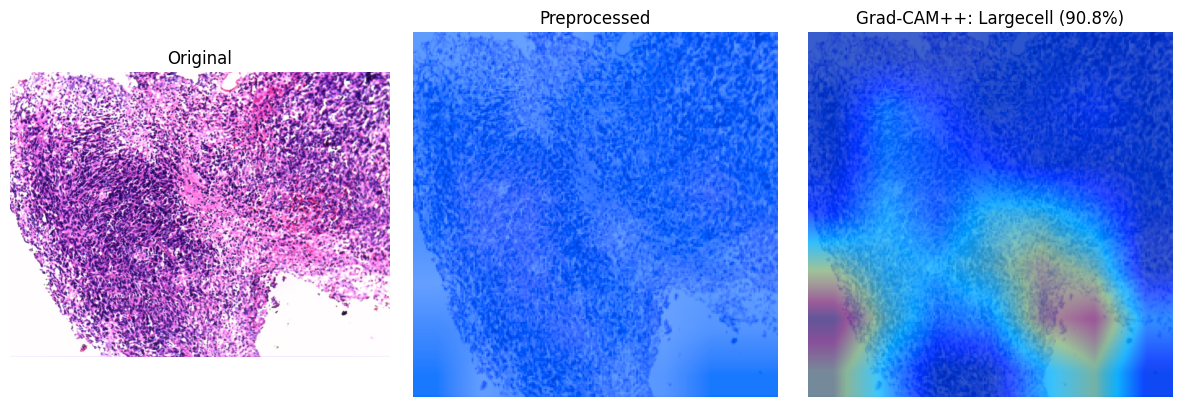

In [ ]:

def make_gradcam_heatmap(img_array, texture_array, model, last_conv_layer_name="backbone_last_conv",
                          pred_index=None, plus_plus=False):
    if BACKBONE_NAME == "ConvNeXtTiny":
        raise ValueError(
            "Grad-CAM is not available for BACKBONE_NAME='ConvNeXtTiny': the TF-Hub feature "
            "extractor used for it (Section 7) returns a pooled embedding, not a spatial "
            "feature map, so there's no conv layer to attribute gradients back to. Retrain with "
            "EfficientNetV2S, ResNet101 or DenseNet201 to use Grad-CAM/Grad-CAM++."
        )
    grad_model = keras.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    inputs = [img_array] if texture_array is None else [img_array, texture_array]

    with tf.GradientTape() as tape1:
        with tf.GradientTape() as tape2:
            with tf.GradientTape() as tape3:
                conv_out, preds = grad_model(inputs)
                if pred_index is None:
                    pred_index = tf.argmax(preds[0])
                class_channel = preds[:, pred_index]
            grads = tape3.gradient(class_channel, conv_out)
        d2 = tape2.gradient(grads, conv_out)
    d3 = tape1.gradient(d2, conv_out)

    if plus_plus:
        # Grad-CAM++ weighting (Chattopadhyay et al., 2018)
        numerator = d2
        denominator = 2.0 * d2 + conv_out * d3
        denominator = tf.where(denominator != 0, denominator, tf.ones_like(denominator))
        alpha = numerator / denominator
        weights = tf.reduce_sum(alpha * tf.nn.relu(grads), axis=(1, 2))
    else:
        weights = tf.reduce_mean(grads, axis=(1, 2))

    conv_out = conv_out[0]
    weights = weights[0]
    heatmap = tf.reduce_sum(tf.multiply(weights, conv_out), axis=-1)
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def overlay_heatmap(img_rgb_uint8, heatmap, alpha=0.4):
    heatmap_resized = cv2.resize(heatmap, (img_rgb_uint8.shape[1], img_rgb_uint8.shape[0]))
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    return cv2.addWeighted(img_rgb_uint8, 1 - alpha, heatmap_color, alpha, 0)

def explain_prediction(filepath, model, class_names, plus_plus=True):
    img_bgr = cv2.imread(filepath, cv2.IMREAD_COLOR)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    proc = preprocess_image(img_rgb)
    tex = extract_texture_features(proc) if USE_TEXTURE_BRANCH else None

    img_batch = np.expand_dims(proc.astype(np.float32), axis=0)
    tex_batch = np.expand_dims(tex, axis=0) if tex is not None else None

    probs = model.predict([img_batch, tex_batch] if tex_batch is not None else [img_batch], verbose=0)[0]
    pred_idx = int(np.argmax(probs))

    heatmap = make_gradcam_heatmap(img_batch, tex_batch, model, pred_index=pred_idx, plus_plus=plus_plus)
    overlay = overlay_heatmap(proc, heatmap)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(img_rgb); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(proc); axes[1].set_title("Preprocessed"); axes[1].axis("off")
    axes[2].imshow(overlay); axes[2].set_title(f"Grad-CAM++: {class_names[pred_idx]} ({probs[pred_idx]:.1%})"); axes[2].axis("off")
    plt.tight_layout()
    plt.show()
    return class_names[pred_idx], probs

# Example: run Grad-CAM++ on the first available test image.
if len(test_df) > 0:
    pred_label, pred_probs = explain_prediction(test_df.iloc[0]["filepath"], model, CLASS_NAMES)
else:
    print("[warn] test_df is empty - the fixed split in Section 3 sent every patient to "
          "train/val this run. Nothing to demo Grad-CAM on until that changes.")


In [ ]:

# --- Handcrafted-feature importance -----------------------------------------------------------------
# Grad-CAM only explains the deep stream. For the texture stream, permutation importance on a
# held-out batch tells you which GLCM/LBP statistics the fusion head actually relies on -
# useful for sanity-checking that the model isn't leaning entirely on staining artifacts.

TEXTURE_FEATURE_NAMES = (
    [f"glcm_{p}_a{i}" for p in ["contrast","dissimilarity","homogeneity","energy","correlation","ASM"] for i in range(4)]
    + [f"lbp_bin{i}" for i in range(10)]
)
assert len(TEXTURE_FEATURE_NAMES) == TEXTURE_FEATURE_DIM

def texture_permutation_importance(model, val_images, val_textures, val_labels_idx, n_repeats=5):
    rng = np.random.default_rng(SEED)
    baseline_preds = np.argmax(model.predict([val_images, val_textures], verbose=0), axis=1)
    baseline_acc = np.mean(baseline_preds == val_labels_idx)

    importances = []
    for i in range(val_textures.shape[1]):
        drops = []
        for _ in range(n_repeats):
            permuted = val_textures.copy()
            rng.shuffle(permuted[:, i])
            preds = np.argmax(model.predict([val_images, permuted], verbose=0), axis=1)
            acc = np.mean(preds == val_labels_idx)
            drops.append(baseline_acc - acc)
        importances.append(np.mean(drops))

    order = np.argsort(importances)[::-1]
    for idx in order[:15]:
        print(f"{TEXTURE_FEATURE_NAMES[idx]:>20s}: mean accuracy drop = {importances[idx]:.4f}")
    return dict(zip(TEXTURE_FEATURE_NAMES, importances))

def dataset_to_arrays(ds):
    # Materializes a tf.data Dataset of (dict-of-tensors, one-hot label) batches into plain
    # NumPy arrays, since texture_permutation_importance needs to shuffle individual feature
    # columns directly rather than working through the tf.data graph.
    images, textures, labels = [], [], []
    for batch_inputs, batch_labels in ds:
        images.append(batch_inputs["image_input"].numpy())
        textures.append(batch_inputs["texture_input"].numpy())
        labels.append(np.argmax(batch_labels.numpy(), axis=1))
    return np.concatenate(images), np.concatenate(textures), np.concatenate(labels)

if USE_TEXTURE_BRANCH and len(val_df) > 0:
    val_images_array, val_textures_array, val_labels_idx = dataset_to_arrays(val_ds)
    texture_importance = texture_permutation_importance(model, val_images_array, val_textures_array, val_labels_idx)
else:
    print("[warn] Skipping texture permutation importance: needs USE_TEXTURE_BRANCH=True and a "
          "non-empty val_df (check Section 3's split output for this run).")


glcm_dissimilarity_a2: mean accuracy drop = 0.0444
    glcm_contrast_a1: mean accuracy drop = 0.0349
 glcm_homogeneity_a2: mean accuracy drop = 0.0222
 glcm_correlation_a3: mean accuracy drop = 0.0222
            lbp_bin9: mean accuracy drop = 0.0159
            lbp_bin5: mean accuracy drop = 0.0159
 glcm_homogeneity_a0: mean accuracy drop = 0.0127
      glcm_energy_a3: mean accuracy drop = 0.0127
            lbp_bin4: mean accuracy drop = 0.0095
            lbp_bin3: mean accuracy drop = 0.0095
glcm_dissimilarity_a3: mean accuracy drop = 0.0095
      glcm_energy_a1: mean accuracy drop = 0.0063
            lbp_bin8: mean accuracy drop = 0.0032
      glcm_energy_a0: mean accuracy drop = 0.0000
 glcm_homogeneity_a3: mean accuracy drop = 0.0000


## 10b. Leave-One-Patient-Out Cross-Validation (the evaluation to actually trust)

With only 11 unique patients across 4 classes (Normal: 1, Largecell: 2, Desmoplastic_Nodular: 3,
Classic: 5), the single fixed train/val/test split from Section 3 strands whole classes out of val
or test, so Section 9's numbers are close to meaningless. Leave-one-patient-out cross-validation
(LOPO) trains on 10 patients, tests on the 1 left out, and repeats for all 11.

**Protocol (changed from the earlier version of this notebook).** There is no inner validation
split. An earlier version carved 15% of the training patients off for EarlyStopping, which could
remove a whole class (Largecell has two patients) from a fold's training data. Every fold now
trains for a fixed number of epochs on all other patients. The only fold that lacks a class in
training is the one holding out Normal (a single group), which is flagged `evaluable=False` and
left out of the summary numbers.

**Arms.** `LOPO_ARMS` below runs the same protocol with the texture stream on and off (ablation) and
with the backbone fine-tuned (top 30% of layers, BatchNorm frozen). Preprocessing (stain
normalisation, CLAHE, GLCM/LBP) is computed once and cached, which makes each fold much faster than
rebuilding it every epoch. Add seeds to `LOPO_SEEDS` to repeat arms: one patient moves patient-level
accuracy by 10 points, so single-seed differences of one or two patients are noise.

**Reading the summary.** `patient_acc` and `patient_bal_acc` use one majority-vote call per patient.
`always_classic_acc` is the score of always predicting Classic over the same evaluable patients.
`mean_train_acc` is the last-epoch training accuracy (with augmentation on); a large gap between it
and held-out accuracy indicates the model is memorising patients. Normal cannot be held out and still
be learned, so this is a ceiling the dataset imposes.


In [ ]:
from sklearn.model_selection import LeaveOneGroupOut
import time, gc

# Tuple-returning version, kept because the Path Foundation LOPO in Section 10c calls it.
def compute_class_weight_safe(y_train_idx, num_classes):
    # A class with only 1-2 total patients can end up with ZERO examples in a given fold's
    # training set once one patient is held out (or, with only 2 left, the inner validation
    # split can claim both). compute_class_weight() hard-errors if a requested class isn't in
    # y at all - this computes weights only over classes actually present, and gives any
    # missing class a nominal weight of 1.0 (harmless: there's nothing of that class for the
    # gradient to touch in this fold anyway).
    present_classes = np.unique(y_train_idx)
    missing_classes = sorted(set(range(num_classes)) - set(present_classes))
    if missing_classes:
        print(f"  [warn] this fold's training set has ZERO examples of class index/indices "
              f"{missing_classes} - the model cannot learn that class in this fold, so its "
              f"result is not comparable to folds where every class was trainable.")
    weights = compute_class_weight('balanced', classes=present_classes, y=y_train_idx)
    weight_dict = {c: 1.0 for c in range(num_classes)}
    weight_dict.update(dict(zip(present_classes, weights)))
    return weight_dict, bool(missing_classes)

# ---- LOPO settings ---------------------------------------------------------------------------
LOPO_SEEDS = [SEED]      # e.g. [42, 43, 44] to repeat every arm; one patient = ~10 points of patient accuracy
LOPO_ARMS = {            # name -> kwargs for lopo_dsaf(); delete an entry to skip that arm
    "texture_on":          dict(use_texture=True,  fine_tune=False, color_jitter=False),
    "texture_off":         dict(use_texture=False, fine_tune=False, color_jitter=False),
    "texture_on_finetune": dict(use_texture=True,  fine_tune=True,  color_jitter=False),
    # Optional: the original augment() uses max_delta=0.08 on 0-255 pixels, i.e. no real brightness
    # jitter. This arm uses +-20 instead (about 8% of the range). Left off by default.
    # "texture_on_colorjitter": dict(use_texture=True, fine_tune=False, color_jitter=True),
}
FT_FRACTION = 0.7        # same top-30%-unfrozen rule as Section 8

# ---- one-time cache of the deterministic preprocessing ---------------------------------------
# Stain normalisation, CLAHE and the GLCM/LBP vector depend only on the image, so compute them once
# instead of per image per epoch.
file_df = file_df.reset_index(drop=True)
if "split_group" not in file_df.columns:
    file_df["split_group"] = file_df["patient_id"].map(lambda s: PATIENT_GROUP_OVERRIDES.get(s, s))

_prep = []
for fp in file_df["filepath"]:
    rgb = cv2.cvtColor(cv2.imread(fp, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    img = preprocess_image(rgb)
    _prep.append((img, extract_texture_features(img)))
IMGS = np.stack([p[0] for p in _prep]).astype(np.uint8)    # (N, H, W, 3)
TEX = np.stack([p[1] for p in _prep]).astype(np.float32)   # (N, TEXTURE_FEATURE_DIM)
LABELS = file_df["label"].map(label_to_idx).values.astype(int)
del _prep
print("cached:", IMGS.shape, TEX.shape)

def _cast(inputs, y):
    out = dict(inputs); out["image_input"] = tf.cast(out["image_input"], tf.float32)
    return out, y

def _augment(inputs, y, color_jitter):
    img = inputs["image_input"]
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.rot90(img, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    # Pixels are 0-255, so the original max_delta=0.08 moved brightness by ~0.03% of the range
    # (no colour augmentation in practice). color_jitter=False keeps that behaviour so arms stay
    # comparable with earlier runs; True uses +-20.
    img = tf.image.random_brightness(img, max_delta=20.0 if color_jitter else 0.08)
    img = tf.image.random_contrast(img, 0.9, 1.1)
    img = tf.clip_by_value(img, 0.0, 255.0)
    out = dict(inputs); out["image_input"] = img
    return out, y

def _make_ds(idx, training, use_texture, color_jitter, seed):
    feats = {"image_input": IMGS[idx]}
    if use_texture:
        feats["texture_input"] = TEX[idx]
    ds = tf.data.Dataset.from_tensor_slices((feats, np.eye(NUM_CLASSES, dtype=np.float32)[LABELS[idx]]))
    if training:
        ds = ds.shuffle(len(idx), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(_cast, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: _augment(x, y, color_jitter), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def _balanced_cw(y_train):
    present = np.unique(y_train)
    w = len(y_train) / (len(present) * np.bincount(y_train, minlength=NUM_CLASSES)[present])
    cw = {c: 1.0 for c in range(NUM_CLASSES)}            # absent class: nominal weight, nothing to learn
    cw.update({int(c): float(v) for c, v in zip(present, w)})
    return cw

def _compile(m, lr):
    m.compile(optimizer=optimizers.Adam(learning_rate=lr),
              loss="categorical_crossentropy", metrics=["accuracy"])

def _unfreeze_top(backbone, fraction=FT_FRACTION):
    backbone.trainable = True
    if isinstance(backbone, hub.KerasLayer):             # opaque SavedModel: trains as one block
        return
    cut = int(len(backbone.layers) * fraction)
    for layer in backbone.layers[:cut]:
        layer.trainable = False
    for layer in backbone.layers[cut:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False                      # keep BN statistics fixed on tiny data

def lopo_dsaf(use_texture=True, fine_tune=False, color_jitter=False, seed=SEED,
              epochs_head=EPOCHS_HEAD, epochs_ft=EPOCHS_FINE_TUNE, only_folds=None, tag=None):
    # Leave-one-patient-out with NO inner validation split: each fold trains for a fixed number of
    # epochs on every other patient, so no class can be removed from training by a validation draw.
    # The fold holding out a single-group class (Normal) is flagged evaluable=False.
    groups = file_df["split_group"].values
    rows = []
    for fold, (tr, te) in enumerate(LeaveOneGroupOut().split(np.zeros((len(LABELS), 1)), LABELS, groups)):
        if only_folds is not None and fold not in only_folds:
            continue
        t0 = time.time()
        tf.random.set_seed(seed); np.random.seed(seed)
        held = int(LABELS[te][0])
        evaluable = held in set(LABELS[tr].tolist())
        cw = _balanced_cw(LABELS[tr])
        train_ds = _make_ds(tr, True, use_texture, color_jitter, seed)
        test_ds = _make_ds(te, False, use_texture, color_jitter, seed)

        model_f, backbone_f = build_dsaf_net(use_texture_branch=use_texture)
        _compile(model_f, LEARNING_RATE_HEAD)
        h = model_f.fit(train_ds, epochs=epochs_head, class_weight=cw, verbose=0)
        train_acc = h.history["accuracy"][-1]
        if fine_tune:
            _unfreeze_top(backbone_f)
            _compile(model_f, LEARNING_RATE_FINE_TUNE)
            h = model_f.fit(train_ds, epochs=epochs_ft, class_weight=cw, verbose=0)
            train_acc = h.history["accuracy"][-1]        # last epoch, measured with augmentation on

        pred = np.argmax(model_f.predict(test_ds, verbose=0), axis=1)
        vote = int(np.bincount(pred, minlength=NUM_CLASSES).argmax())
        rows.append(dict(fold=fold, patient=groups[te][0], true=held, vote=vote, n_tiles=len(te),
                         n_correct=int((pred == LABELS[te]).sum()), train_acc=float(train_acc),
                         evaluable=evaluable))
        print(f"[{fold+1}] {groups[te][0]:>6} ({CLASS_NAMES[held]:<22}) vote={CLASS_NAMES[vote]:<22} "
              f"tile acc={rows[-1]['n_correct']/len(te):.2f} train acc={train_acc:.2f} "
              f"{'' if evaluable else '[not evaluable] '}{time.time()-t0:.0f}s")
        del model_f, backbone_f, train_ds, test_ds
        keras.backend.clear_session(); gc.collect()

    df_ = pd.DataFrame(rows)
    if tag:
        df_.to_csv(os.path.join(OUTPUT_DIR, f"dsaf_lopo_{tag}.csv"), index=False)
    return df_

def summarize_lopo(df_, name=""):
    ev = df_[df_.evaluable]
    t, v = ev["true"].values, ev["vote"].values
    per_class = [np.mean(v[t == c] == c) for c in np.unique(t)]
    return pd.Series(dict(
        arm=name, n_evaluable=len(ev), patients_correct=f"{int((v == t).sum())}/{len(ev)}",
        patient_acc=np.mean(v == t), patient_bal_acc=np.mean(per_class),
        always_classic_acc=np.mean(t == label_to_idx["Classic"]),
        always_classic_bal_acc=1 / len(np.unique(t)),
        tile_acc_pooled=ev.n_correct.sum() / ev.n_tiles.sum(),
        mean_train_acc=df_.train_acc.mean()))

# ---- run the arms -------------------------------------------------------------------------------
lopo_runs = {}
for arm, kw in LOPO_ARMS.items():
    for s in LOPO_SEEDS:
        print(f"\n=== arm: {arm} | seed {s} ===")
        lopo_runs[(arm, s)] = lopo_dsaf(seed=s, tag=f"{arm}_s{s}", **kw)

summary = pd.DataFrame([summarize_lopo(d_, f"{arm} (seed {s})") for (arm, s), d_ in lopo_runs.items()]).set_index("arm")
print("\nDSAF-Net LOPO summary (Normal fold excluded; one majority-vote call per patient):")
print(summary.round(3).to_string())
summary.to_csv(os.path.join(OUTPUT_DIR, "dsaf_lopo_summary.csv"))

# Per-patient calls for the first arm (texture on, stage 1): who was right, who was wrong.
_first = next(iter(lopo_runs.values()))
print("\nPer-patient calls, first arm:")
print(_first.assign(true=_first.true.map(dict(enumerate(CLASS_NAMES))),
                    vote=_first.vote.map(dict(enumerate(CLASS_NAMES))),
                    tile_acc=(_first.n_correct / _first.n_tiles).round(2))
      [["patient", "true", "vote", "n_tiles", "tile_acc", "train_acc", "evaluable"]].to_string(index=False))

# Backwards-compatible name used elsewhere in the notebook (first arm, first seed).
lopo_results = _first.assign(
    held_out_patient=_first.patient, true_label=_first.true.map(dict(enumerate(CLASS_NAMES))),
    n_images=_first.n_tiles, accuracy=_first.n_correct / _first.n_tiles,
    majority_vote_label=_first.vote.map(dict(enumerate(CLASS_NAMES))),
    majority_vote_correct=(_first.vote == _first.true).astype(int),
    missing_class_in_train=~_first.evaluable)


cached: (357, 224, 224, 3) (357, 34)

=== arm: texture_on | seed 42 ===
[1]    141 (Desmoplastic_Nodular  ) vote=Classic                tile acc=0.00 train acc=0.81 39s
[2]  17126 (Largecell             ) vote=Desmoplastic_Nodular   tile acc=0.30 train acc=0.79 39s
[3]   1766 (Classic               ) vote=Classic                tile acc=0.50 train acc=0.77 38s
[4]    188 (Classic               ) vote=Classic                tile acc=0.65 train acc=0.78 38s
[5]    203 (Desmoplastic_Nodular  ) vote=Desmoplastic_Nodular   tile acc=0.67 train acc=0.79 38s
[6]    277 (Classic               ) vote=Classic                tile acc=0.36 train acc=0.81 38s
[7]    279 (Classic               ) vote=Classic                tile acc=0.68 train acc=0.82 37s
[8]    321 (Classic               ) vote=Desmoplastic_Nodular   tile acc=0.34 train acc=0.82 37s
[9]    395 (Largecell             ) vote=Classic                tile acc=0.07 train acc=0.77 36s
[10]    411 (Desmoplastic_Nodular  ) vote=Classic      


## 10c. Alternative Deep Stream: Google Path Foundation Embeddings (Frozen)

Section 7's backbones are all ImageNet-pretrained - tuned for natural photos, not H&E
histology. The near-chance LOPO-CV result above could be due to that domain mismatch
compounding the small-patient-count problem (a hypothesis this section tests, not an established cause): the model may be overfitting to patient-specific
staining/scanner artifacts rather than learning subtype morphology, and an ImageNet backbone
gives it less of a head start on the latter than a histopathology-pretrained one would.

[Path Foundation](https://huggingface.co/google/path-foundation) is a real option here: a
self-supervised ViT-S, trained by Google on 60M real H&E patches across 32 TCGA tumor types,
distributed as a native TF-Keras SavedModel (no PyTorch, so it doesn't reintroduce the
PyTorch/TensorFlow DLL conflicts noted elsewhere in this project). It reports a 93% linear-probe
AUC across a suite of histopathology classification benchmarks - exactly the "train a small
classifier on frozen embeddings" regime this 11-patient dataset needs.

**Two trade-offs versus Section 7, both structural, not oversights:**
1. **It's frozen, not fine-tunable.** Path Foundation exposes only a serving signature (no
   gradient access) - there's no way to unfreeze and fine-tune it the way Section 8 does with
   EfficientNetV2S/ResNet101/DenseNet201. In practice this is arguably the *right* regime for
   11 patients anyway (fewer trainable parameters = less to overfit), which is exactly what its
   own documentation recommends it for.
2. **No spatial feature map, so no CBAM and no Grad-CAM** - same limitation as the ConvNeXtTiny
   path in Section 7, for the same reason: the model returns a single pooled 384-dim embedding
   per image, not a (H, W, C) tensor. If Grad-CAM-style explainability on this backbone matters
   later, a gradient-free saliency method (e.g. occlusion/RISE) would be the way to get it - not
   implemented here.

**Embeddings come from a cache here.** Path Foundation could not be loaded under TF 2.9.1 in this
environment, so its embeddings were computed in Colab (`pathfoundation_colab.ipynb`, same Reinhard +
CLAHE preprocessing) and saved as `outputs/feature_cache/pathfoundation__stain+clahe.npz`. The cells
below read that file, matched to `file_df` by folder and file name, and skip the Hugging Face login
when it exists. The setup list is only needed if you compute embeddings locally.

**Setup required to compute embeddings locally** (this is gated, unlike the public TF-Hub ConvNeXt path):
1. Create a Hugging Face account if you don't have one, visit
   https://huggingface.co/google/path-foundation while logged in, and accept the Health AI
   Developer Foundations terms of use (approved immediately, one click).
2. Create a read-access token at https://huggingface.co/settings/tokens.
3. In this environment: `pip install huggingface_hub`, then either run
   `huggingface_hub.login()` once interactively (it prompts for the token), or set the
   `HF_TOKEN` environment variable before launching Jupyter.

If you'd rather not deal with the gated access right now, skip this section entirely - nothing
downstream in the notebook requires it; Sections 12/13 still export/deploy `final_model` from
Section 11b (the EfficientNetV2S-based DSAF-Net), not anything built here.


In [ ]:
PF_CACHE_NPZ = os.path.join(OUTPUT_DIR, "feature_cache", "pathfoundation__stain+clahe.npz")
if os.path.exists(PF_CACHE_NPZ):
    print("Path Foundation embeddings found in the cache (computed in Colab) - Hugging Face login not needed.")
else:
    from huggingface_hub import login
    login()

Path Foundation embeddings found in the cache (computed in Colab) - Hugging Face login not needed.


In [ ]:
if not os.path.exists(PF_CACHE_NPZ):
    from huggingface_hub import whoami
    print(whoami())

In [ ]:
# pip install huggingface_hub --no-deps   (uncomment the next line if not already installed)
# os.system(f'"{sys.executable}" -m pip install -q huggingface_hub --no-deps')

PATH_FOUNDATION_EMBED_DIM = 384

_path_foundation_infer = None  # loaded lazily on first use

def _get_path_foundation_infer():
    global _path_foundation_infer
    if _path_foundation_infer is not None:
        return _path_foundation_infer

    from huggingface_hub import snapshot_download   # only needed when computing embeddings locally
    model_dir = snapshot_download(repo_id="google/path-foundation")

    def _pb_size(d):
        p = os.path.join(d, "saved_model.pb")
        return os.path.getsize(p) if os.path.exists(p) else -1

    # "0 MetaGraphs" means saved_model.pb parsed as empty/partial. 1 KB is a heuristic threshold.
    print(f"Downloaded to: {model_dir}")
    print(f"saved_model.pb: {_pb_size(model_dir):,} bytes")
    if _pb_size(model_dir) < 1024:
        print("saved_model.pb is missing or tiny - forcing a clean re-download ...")
        model_dir = snapshot_download(repo_id="google/path-foundation", force_download=True)
        print(f"saved_model.pb after re-download: {_pb_size(model_dir):,} bytes")
        if _pb_size(model_dir) < 1024:
            raise RuntimeError(
                "saved_model.pb is still empty after a forced re-download. Delete the cached "
                "folder (Windows: %USERPROFILE%\\.cache\\huggingface\\hub\\models--google--path-foundation) "
                "and re-run, and confirm the gated terms were accepted for the account whose "
                "token you logged in with.")
    var_dir = os.path.join(model_dir, "variables")
    print(f"variables/: {sorted(os.listdir(var_dir)) if os.path.isdir(var_dir) else 'MISSING'}")

    try:
        model = tf.saved_model.load(model_dir)
    except Exception:
        print("\ntf.saved_model.load failed even with a non-empty saved_model.pb. If the error "
              "mentions an unregistered op or unknown attribute, the model was exported with a "
              "newer TensorFlow than 2.9.1. Workaround: compute the embeddings in Colab, save "
              "path_foundation_embeddings.npy, and put it in OUTPUT_DIR.")
        raise
    _path_foundation_infer = model.signatures["serving_default"]
    return _path_foundation_infer

def compute_path_foundation_embedding(img_rgb_float_224):
    # img must already be Section 4's preprocess_image() output (224x224, stain-normalized,
    # CLAHE'd). Path Foundation expects [0, 1]-scaled float32 - NOT the ImageNet-style
    # preprocess_input() the Section 7 backbones use, which is why this isn't wired through
    # the same Lambda(preprocess_fn) pattern.
    tensor = tf.cast(tf.expand_dims(img_rgb_float_224, axis=0), tf.float32) / 255.0
    out = _get_path_foundation_infer()(tf.constant(tensor))
    embedding = (out["output_0"] if "output_0" in out else next(iter(out.values()))).numpy().flatten()
    return embedding.astype(np.float32)

def compute_path_foundation_embeddings_for_df(df, cache_path=None):
    # Pure frozen inference, no training - cheap enough to run once over the whole manifest
    # and cache, rather than recomputing per fold inside the LOPO loop below.
    if cache_path and os.path.exists(cache_path):
        print(f"Loading cached embeddings from {cache_path}")
        return np.load(cache_path)
    embeddings = np.zeros((len(df), PATH_FOUNDATION_EMBED_DIM), dtype=np.float32)
    for i, fp in enumerate(df["filepath"].values):
        img_bgr = cv2.imread(fp, cv2.IMREAD_COLOR)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        proc = preprocess_image(img_rgb)
        embeddings[i] = compute_path_foundation_embedding(proc)
        if (i + 1) % 50 == 0:
            print(f"  embedded {i+1}/{len(df)}")
    if cache_path:
        np.save(cache_path, embeddings)
        print(f"Cached embeddings to {cache_path}")
    return embeddings

def build_dsaf_net_pathfoundation(num_classes=NUM_CLASSES, use_texture_branch=USE_TEXTURE_BRANCH):
    # Classifier head on top of frozen Path Foundation embeddings + the same texture stream as
    # Section 7's build_dsaf_net. No CBAM, no spatial map - see the markdown above for why.
    embedding_input = keras.Input(shape=(PATH_FOUNDATION_EMBED_DIM,), name="pathfoundation_embedding_input")
    deep_embedding = layers.BatchNormalization(name="pf_embed_bn")(embedding_input)
    deep_embedding = layers.Dense(128, activation="relu", name="deep_proj")(deep_embedding)
    deep_embedding = layers.Dropout(0.3, name="deep_dropout")(deep_embedding)

    if use_texture_branch:
        texture_input = keras.Input(shape=(TEXTURE_FEATURE_DIM,), name="texture_input")
        t = layers.BatchNormalization(name="texture_bn")(texture_input)
        t = layers.Dense(64, activation="relu", name="texture_dense1")(t)
        t = layers.Dropout(0.2, name="texture_dropout1")(t)
        texture_embedding = layers.Dense(64, activation="relu", name="texture_dense2")(t)
        fused = layers.Concatenate(name="fusion_concat")([deep_embedding, texture_embedding])
        inputs = [embedding_input, texture_input]
    else:
        fused = deep_embedding
        inputs = [embedding_input]

    h = layers.Dense(64, activation="relu", name="fusion_dense")(fused)
    h = layers.BatchNormalization(name="fusion_bn")(h)
    h = layers.Dropout(0.4, name="fusion_dropout")(h)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(h)
    return keras.Model(inputs=inputs, outputs=outputs, name="DSAF_Net_PathFoundation")

def build_pathfoundation_arrays(df, embeddings_lookup, use_texture_branch=USE_TEXTURE_BRANCH):
    emb = np.stack([embeddings_lookup[fp] for fp in df["filepath"].values])
    tex = None
    if use_texture_branch:
        tex = np.zeros((len(df), TEXTURE_FEATURE_DIM), dtype=np.float32)
        for i, fp in enumerate(df["filepath"].values):
            img_bgr = cv2.imread(fp, cv2.IMREAD_COLOR)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            proc = preprocess_image(img_rgb)
            tex[i] = extract_texture_features(proc)
    y = df["label"].map(label_to_idx).values
    return emb, tex, y

# ---- load (or compute) the embeddings for every image in file_df ---------------------------------
PF_CACHE_NPZ = os.path.join(OUTPUT_DIR, "feature_cache", "pathfoundation__stain+clahe.npz")
PF_CACHE_NPY = os.path.join(OUTPUT_DIR, "path_foundation_embeddings.npy")

def _path_key(p):
    # "<magnification folder>/<file name>", lower-case - independent of drive letter, folder, OS
    # separators, so a cache built in Colab matches file_df built on Windows.
    return "/".join(re.split(r"[\\/]+", str(p))[-2:]).lower()

def load_path_foundation_from_npz(df, npz_path):
    z = np.load(npz_path, allow_pickle=False)
    lookup = {_path_key(p): i for i, p in enumerate(z["paths"].tolist())}
    missing = [fp for fp in df["filepath"] if _path_key(fp) not in lookup]
    if missing:
        raise KeyError(f"{len(missing)} of {len(df)} images have no embedding in {npz_path}, e.g. {missing[:3]}")
    return z["feats"][[lookup[_path_key(fp)] for fp in df["filepath"]]].astype(np.float32)

if os.path.exists(PF_CACHE_NPZ):
    if not (USE_STAIN_NORM and USE_CLAHE):
        print("[warn] the cached embeddings were computed with stain normalisation + CLAHE, but one of "
              "USE_STAIN_NORM / USE_CLAHE is False here - the comparison with the DSAF-Net arms is no "
              "longer like for like.")
    path_foundation_embeddings = load_path_foundation_from_npz(file_df, PF_CACHE_NPZ)
    print(f"Loaded Path Foundation embeddings from {PF_CACHE_NPZ}: {path_foundation_embeddings.shape}")
else:
    print(f"[info] {PF_CACHE_NPZ} not found - computing embeddings with the model instead (needs a "
          f"TensorFlow version that can load Path Foundation; this fails on TF 2.9.1).")
    path_foundation_embeddings = compute_path_foundation_embeddings_for_df(file_df, cache_path=PF_CACHE_NPY)
assert path_foundation_embeddings.shape == (len(file_df), PATH_FOUNDATION_EMBED_DIM)
assert not np.isnan(path_foundation_embeddings).any()

Loaded Path Foundation embeddings from ./outputs\feature_cache\pathfoundation__stain+clahe.npz: (357, 384)


In [ ]:
def leave_one_slide_out_cv_pathfoundation(file_df, embeddings_lookup, epochs=30, seed=SEED):
    # Same leave-one-patient-out protocol as Section 10b, but on frozen Path Foundation
    # embeddings + the texture branch instead of a fine-tuned CNN. Each fold trains only a
    # small dense head, so this is fast (seconds per fold, not minutes) - nothing deep is
    # being trained from scratch here. Grouped by split_group (post 1766A/1766B override),
    # same reasoning as Section 10b.
    logo = LeaveOneGroupOut()
    groups = file_df["split_group"].values
    y_all = file_df["label"].map(label_to_idx).values
    emb_all, tex_all, _ = build_pathfoundation_arrays(file_df, embeddings_lookup)

    fold_results = []
    for fold_idx, (train_idx, test_idx) in enumerate(logo.split(file_df, y_all, groups)):
        held_out_patient = file_df.iloc[test_idx]["split_group"].iloc[0]
        held_out_label = file_df.iloc[test_idx]["label"].iloc[0]

        tr_y, te_y = y_all[train_idx], y_all[test_idx]
        tr_emb, te_emb = emb_all[train_idx], emb_all[test_idx]
        inputs_tr = [tr_emb]
        inputs_te = [te_emb]
        if USE_TEXTURE_BRANCH:
            inputs_tr.append(tex_all[train_idx])
            inputs_te.append(tex_all[test_idx])

        cw, fold_missing_a_class = compute_class_weight_safe(tr_y, NUM_CLASSES)
        tr_y_onehot = tf.one_hot(tr_y, NUM_CLASSES).numpy()

        tf.random.set_seed(seed); np.random.seed(seed)
        m = build_dsaf_net_pathfoundation()
        m.compile(optimizer=optimizers.Adam(learning_rate=1e-3),
                   loss="categorical_crossentropy", metrics=["accuracy"])
        h = m.fit(inputs_tr, tr_y_onehot, epochs=epochs, batch_size=16, class_weight=cw, verbose=0)
        train_acc = h.history["accuracy"][-1]

        y_pred = np.argmax(m.predict(inputs_te, verbose=0), axis=1)
        acc = np.mean(y_pred == te_y)
        vote_idx = np.bincount(y_pred, minlength=NUM_CLASSES).argmax()
        majority_correct = int(vote_idx == te_y[0])

        # same schema as lopo_dsaf() (Section 10b) so summarize_lopo() works on both
        fold_results.append({
            "fold": fold_idx, "patient": held_out_patient, "true": int(te_y[0]), "vote": int(vote_idx),
            "n_tiles": len(test_idx), "n_correct": int((y_pred == te_y).sum()),
            "train_acc": float(train_acc), "evaluable": not fold_missing_a_class,
        })
        vote_str = "correct" if majority_correct else f"WRONG (voted {CLASS_NAMES[vote_idx]})"
        print(f"[fold {fold_idx+1}/{file_df['split_group'].nunique()}] held out {held_out_patient} "
              f"({held_out_label}, n={len(test_idx)}): tile acc={acc:.3f}, patient vote={vote_str}")

    return pd.DataFrame(fold_results)

pf_embeddings_lookup = dict(zip(file_df["filepath"].values, path_foundation_embeddings))
lopo_pf_runs = {}
for s in LOPO_SEEDS:
    print(f"\n=== Path Foundation embeddings + dense head | seed {s} ===")
    lopo_pf_runs[s] = leave_one_slide_out_cv_pathfoundation(file_df, pf_embeddings_lookup, seed=s)
    lopo_pf_runs[s].to_csv(os.path.join(OUTPUT_DIR, f"pathfoundation_lopo_s{s}.csv"), index=False)

pf_summary = pd.DataFrame([summarize_lopo(d_, f"path_foundation_head (seed {s})")
                           for s, d_ in lopo_pf_runs.items()]).set_index("arm")
all_summary = pd.concat([summary, pf_summary])
print("\nDSAF-Net arms vs Path Foundation (same LOPO protocol, Normal fold excluded):")
print(all_summary.round(3).to_string())
all_summary.to_csv(os.path.join(OUTPUT_DIR, "lopo_comparison_summary.csv"))

# Per-patient calls, first DSAF-Net arm vs Path Foundation, first seed
_pf = lopo_pf_runs[LOPO_SEEDS[0]]
_cmp = _first[["patient", "true", "vote"]].rename(columns={"vote": "dsaf_vote"}).merge(
    _pf[["patient", "vote"]].rename(columns={"vote": "pf_vote"}), on="patient")
for col in ["true", "dsaf_vote", "pf_vote"]:
    _cmp[col] = _cmp[col].map(dict(enumerate(CLASS_NAMES)))
print("\nPer-patient calls:"); print(_cmp.to_string(index=False))
print("\nThe row to compare is patient_acc / patient_bal_acc against always_classic_*: a representation "
      "only helps if it beats those by more than a patient or two, consistently across seeds.")



=== Path Foundation embeddings + dense head | seed 42 ===
[fold 1/11] held out 141 (Desmoplastic_Nodular, n=25): tile acc=0.240, patient vote=WRONG (voted Classic)
[fold 2/11] held out 17126 (Largecell, n=10): tile acc=0.400, patient vote=WRONG (voted Desmoplastic_Nodular)
[fold 3/11] held out 1766 (Classic, n=20): tile acc=0.450, patient vote=correct
[fold 4/11] held out 188 (Classic, n=17): tile acc=0.471, patient vote=correct
[fold 5/11] held out 203 (Desmoplastic_Nodular, n=24): tile acc=0.083, patient vote=WRONG (voted Classic)
[fold 6/11] held out 277 (Classic, n=11): tile acc=0.273, patient vote=WRONG (voted Desmoplastic_Nodular)
[fold 7/11] held out 279 (Classic, n=37): tile acc=0.432, patient vote=correct
[fold 8/11] held out 321 (Classic, n=56): tile acc=0.357, patient vote=WRONG (voted Desmoplastic_Nodular)
[fold 9/11] held out 395 (Largecell, n=44): tile acc=0.159, patient vote=WRONG (voted Classic)
[fold 10/11] held out 411 (Desmoplastic_Nodular, n=38): tile acc=0.000, pa


## 11. Optional Extension: Lightweight Ensemble (`USE_ENSEMBLE_EXTENSION`)

A scaled-down nod to the CNN-ensemble papers (CoMB-Deep's 10-CNN Bi-LSTM fusion; the
EfficientNet-B0/B3/B7 ECOC ensemble; the ResNet-50/MobileNetV2/Xception majority-vote ensemble).
Rather than training 3-10 heavy backbones — infeasible on a 6 GB GPU without gradient
checkpointing and long training times — this trains one additional lightweight backbone
(MobileNetV3-Small) as a second DSAF-Net and soft-votes its output probabilities with the
primary model. Leave `USE_ENSEMBLE_EXTENSION = False` unless you have the compute budget (or are
running this on Colab/a larger GPU) to train two full models.


In [ ]:

if USE_ENSEMBLE_EXTENSION:
    model_secondary, backbone_secondary = build_dsaf_net(backbone_name="DenseNet201")
    compile_model(model_secondary, LEARNING_RATE_HEAD)
    # history_secondary = model_secondary.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
    #                                          class_weight=class_weights, callbacks=get_callbacks("secondary_warmup"))
    # (repeat the fine-tuning stage from Section 8 for model_secondary if desired)

    def ensemble_predict(models_list, weights_list, ds):
        all_probs = [w * m.predict(ds) for m, w in zip(models_list, weights_list)]
        return np.sum(all_probs, axis=0)

    # ensemble_probs = ensemble_predict([model, model_secondary], [0.6, 0.4], test_ds)
    print("Ensemble extension enabled - remember to train model_secondary before using ensemble_predict.")
else:
    print("Ensemble extension disabled (USE_ENSEMBLE_EXTENSION = False). Using the single DSAF-Net model.")


Ensemble extension disabled (USE_ENSEMBLE_EXTENSION = False). Using the single DSAF-Net model.



## 11b. Final Deployment Model (Trained on All 11 Patients)

`model` (Sections 7-8) and the fold models inside `lopo_dsaf` (Section 10b) all
exist to *measure* the pipeline - none of them is the model you'd actually ship. LOPO-CV's whole
point was to estimate expected accuracy without permanently sacrificing any data as a held-out
set; once you have that estimate, there's no reason to keep withholding patients from the model
you deploy. This cell trains fresh on **all 11 patients, nothing held out**, and produces
`final_model` - the object Sections 12 and 13 actually export and serve.

Without a validation split there's no `val_loss` for EarlyStopping/ReduceLROnPlateau to watch, so
this uses a fixed epoch count instead (`EPOCHS_HEAD`/`EPOCHS_FINE_TUNE` from Section 2) and a
loss-only ReduceLROnPlateau. Section 10b also trains for a fixed number of epochs (no validation curves), so these epoch
counts are not tuned on held-out data, and there is no held-out signal here to catch overfitting
if they are set too high.


In [ ]:

def get_callbacks_no_val(tag):
    # no EarlyStopping here - there's no held-out split left to justify stopping against
    return [
        callbacks.ReduceLROnPlateau(monitor="loss", factor=0.5, patience=3, min_lr=1e-7),
        callbacks.ModelCheckpoint(os.path.join(OUTPUT_DIR, f"dsaf_net_{tag}.keras"),
                                   monitor="loss", save_best_only=True),
        callbacks.CSVLogger(os.path.join(OUTPUT_DIR, f"training_log_{tag}.csv")),
    ]

final_train_ds = make_dataset(file_df, training=True)

full_class_weights = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES),
                                           y=file_df["label"].map(label_to_idx).values)
full_class_weights = dict(enumerate(full_class_weights))

final_model, final_backbone = build_dsaf_net()

# --- Stage 1: frozen backbone -----------------------------------------------------------------
compile_model(final_model, LEARNING_RATE_HEAD)
final_model.fit(final_train_ds, epochs=EPOCHS_HEAD, class_weight=full_class_weights,
                 callbacks=get_callbacks_no_val("final_warmup"))

# --- Stage 2: fine-tune the top of the backbone (mirrors Section 8) ---------------------------
if isinstance(final_backbone, hub.KerasLayer):
    final_backbone.trainable = True
    print("ConvNeXtTiny (TF-Hub) has no sub-layers to freeze selectively - fine-tuning the "
          "whole module at LEARNING_RATE_FINE_TUNE.")
else:
    final_backbone.trainable = True
    n_layers = len(final_backbone.layers)
    freeze_until = int(n_layers * FINE_TUNE_AT_FRACTION)
    for layer in final_backbone.layers[:freeze_until]:
        layer.trainable = False
    for layer in final_backbone.layers[freeze_until:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    print(f"Backbone: {n_layers} layers total, {n_layers - freeze_until} unfrozen for fine-tuning.")

compile_model(final_model, LEARNING_RATE_FINE_TUNE)
final_model.fit(final_train_ds, epochs=EPOCHS_FINE_TUNE, class_weight=full_class_weights,
                 callbacks=get_callbacks_no_val("final_finetune"))


Epoch 1/15
23/23 [==============================] - 20s 396ms/step - loss: 1.3504 - accuracy: 0.4538 - auc: 0.7147 - precision: 0.4946 - recall: 0.3866 - lr: 0.0010
Epoch 2/15
23/23 [==============================] - 9s 392ms/step - loss: 0.9572 - accuracy: 0.5714 - auc: 0.8226 - precision: 0.6318 - recall: 0.5238 - lr: 0.0010
Epoch 3/15
23/23 [==============================] - 9s 392ms/step - loss: 0.7886 - accuracy: 0.6583 - auc: 0.8687 - precision: 0.7148 - recall: 0.5966 - lr: 0.0010
Epoch 4/15
23/23 [==============================] - 9s 364ms/step - loss: 0.8146 - accuracy: 0.6443 - auc: 0.8679 - precision: 0.6808 - recall: 0.5854 - lr: 0.0010
Epoch 5/15
23/23 [==============================] - 9s 387ms/step - loss: 0.7479 - accuracy: 0.6947 - auc: 0.8849 - precision: 0.7305 - recall: 0.6303 - lr: 0.0010
Epoch 6/15
23/23 [==============================] - 9s 394ms/step - loss: 0.6917 - accuracy: 0.6779 - auc: 0.8987 - precision: 0.7375 - recall: 0.6218 - lr: 0.0010
Epoch 7/15
23/2


## 12. Export the Model for Deployment

Exports `final_model` (Section 11b) - the model trained on all 11 patients - not `model` from
Section 7/8, which only ever saw the fixed-split subset and exists for diagnostics.

Saves three artifacts to `OUTPUT_DIR`:
1. `dsaf_net_final.keras` - native Keras format (best for reloading inside another notebook/Flask app).
2. `dsaf_net_saved_model/` - TensorFlow `SavedModel` format (best for TF Serving).
3. `dsaf_net.tflite` - quantized TFLite model (best for a lightweight/mobile/edge deployment).

Also saves `class_names.json` and the preprocessing config so a deployment script doesn't need
to re-import this whole notebook.


In [ ]:
FINAL_MODEL_PATH_SAVEDMODEL = os.path.join(OUTPUT_DIR, "dsaf_net_saved_model")
FINAL_MODEL_PATH_TFLITE = os.path.join(OUTPUT_DIR, "dsaf_net.tflite")

def export_model(m):
    # TF 2.9.1 has neither Model.export() (added 2.13+) nor the native ".keras" zip format
    # (added ~2.12+) - the SavedModel directory format is what this TF version actually
    # supports, and it's fully sufficient for reloading (tf.keras.models.load_model(path)
    # works on it directly) and for TFLite conversion below. It's also the format already
    # known to sidestep the h5py name-collision issue hit on Windows previously.
    m.save(FINAL_MODEL_PATH_SAVEDMODEL, save_format="tf")

    converter = tf.lite.TFLiteConverter.from_saved_model(FINAL_MODEL_PATH_SAVEDMODEL)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()
    with open(FINAL_MODEL_PATH_TFLITE, "wb") as f:
        f.write(tflite_model)

    with open(os.path.join(OUTPUT_DIR, "class_names.json"), "w") as f:
        json.dump(CLASS_NAMES, f)

    with open(os.path.join(OUTPUT_DIR, "preprocess_config.json"), "w") as f:
        json.dump({
            "img_size": IMG_SIZE, "use_stain_norm": USE_STAIN_NORM, "use_clahe": USE_CLAHE,
            "use_texture_branch": USE_TEXTURE_BRANCH, "texture_feature_dim": TEXTURE_FEATURE_DIM,
            "backbone": BACKBONE_NAME,
        }, f)

    print(f"Saved: {FINAL_MODEL_PATH_SAVEDMODEL}\n       {FINAL_MODEL_PATH_TFLITE}")

export_model(final_model)

INFO:tensorflow:Assets written to: ./outputs\dsaf_net_saved_model\assets


INFO:tensorflow:Assets written to: ./outputs\dsaf_net_saved_model\assets


Saved: ./outputs\dsaf_net_saved_model
       ./outputs\dsaf_net.tflite



## 13. Deployment: Gradio App (Upload an Image → Subtype + Grad-CAM)

Runs inline in the notebook (`demo.launch()`), and can be pushed as-is to a Hugging Face Space
for a standalone hosted deployment (upload this notebook's exported `app.py` equivalent — see
the commented Flask alternative below the Gradio block for a plain-Python API instead).

Install Gradio if it isn't already available: `pip install gradio`.


In [ ]:

import gradio as gr

def gradio_predict(uploaded_image):
    # uploaded_image arrives as an RGB numpy array from Gradio's Image component.
    img_rgb = uploaded_image
    proc = preprocess_image(img_rgb)
    tex = extract_texture_features(proc) if USE_TEXTURE_BRANCH else None

    img_batch = np.expand_dims(proc.astype(np.float32), axis=0)
    tex_batch = np.expand_dims(tex, axis=0) if tex is not None else None

    inputs = [img_batch, tex_batch] if tex_batch is not None else [img_batch]
    probs = final_model.predict(inputs, verbose=0)[0]
    pred_idx = int(np.argmax(probs))

    heatmap = make_gradcam_heatmap(img_batch, tex_batch, final_model, pred_index=pred_idx, plus_plus=True)
    overlay = overlay_heatmap(proc, heatmap)

    confidence_dict = {CLASS_NAMES[i]: float(probs[i]) for i in range(NUM_CLASSES)}
    return confidence_dict, overlay

demo = gr.Interface(
    fn=gradio_predict,
    inputs=gr.Image(label="Upload a histopathology tile (H&E, PNG/JPG)"),
    outputs=[
        gr.Label(num_top_classes=NUM_CLASSES, label="Predicted subtype"),
        gr.Image(label="Grad-CAM++ overlay (region driving the prediction)"),
    ],
    title="Medulloblastoma Histopathology Subtype Classifier (DSAF-Net)",
    description=(
        "Research/teaching prototype - not a validated diagnostic tool. Upload a single H&E "
        "histopathology tile to get a predicted WHO subtype and a Grad-CAM++ explanation of the "
        "region the model used."
    ),
    examples=None,  # populate with a few sample filepaths from file_df once available
)

demo.launch()  # add share=True for a temporary public link


Running on local URL:  http://127.0.0.1:7860

To create a public link, set `share=True` in `launch()`.


IMPORTANT: You are using gradio version 3.50.2, however version 4.44.1 is available, please upgrade.
--------



### Alternative: a minimal Flask API for non-Gradio deployment

If you need a plain REST endpoint (e.g. to call from a separate front-end) instead of the Gradio
UI, the equivalent Flask app is:

```python
from flask import Flask, request, jsonify
import numpy as np, cv2

app = Flask(__name__)
# model, CLASS_NAMES, preprocess_image, extract_texture_features loaded/imported here

@app.route("/predict", methods=["POST"])
def predict():
    file = request.files["image"]
    img_arr = np.frombuffer(file.read(), np.uint8)
    img_bgr = cv2.imdecode(img_arr, cv2.IMREAD_COLOR)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    proc = preprocess_image(img_rgb)
    tex = extract_texture_features(proc)
    probs = model.predict([np.expand_dims(proc, 0), np.expand_dims(tex, 0)], verbose=0)[0]
    pred_idx = int(np.argmax(probs))
    return jsonify({"subtype": CLASS_NAMES[pred_idx],
                     "confidence": float(probs[pred_idx]),
                     "all_probabilities": {c: float(p) for c, p in zip(CLASS_NAMES, probs)}})

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)
```

This is not wired into the notebook (no dev server should stay running inside a notebook
process) - copy it into a standalone `app.py` alongside the exported `SavedModel` from
Section 12 if you need it.



## 14. Limitations & Honest Scope Notes

- **Leakage risk depends on your filename convention.** Section 3's patient-level split only
  works if `PATIENT_ID_REGEX` actually matches your files. If it falls back to an image-level
  split, treat any accuracy above the low-to-mid 90s with real suspicion — this is very plausibly
  what inflates several of the >99% figures in the surveyed literature, none of which explicitly
  document a patient-level split.
- **Small-dataset overfitting.** Public medulloblastoma histopathology datasets are small
  (typically hundreds to low thousands of tiles across 4-5 classes). A model this size can
  memorize a training set of that size; the val/test gap in Section 9's classification report is
  the number to watch, not just test accuracy in isolation.
- **Single-institution / single-scanner bias.** Stain normalization (Section 4) helps but does
  not fully solve domain shift. A model trained on tiles from one scanner/lab may not generalize
  to slides digitized elsewhere without external validation data, which this notebook does not
  include by default.
- **Patch-level, not slide-level, inference.** The Gradio app in Section 13 classifies one tile
  at a time. A real diagnostic workflow classifies many tiles per whole-slide image and
  aggregates (e.g. majority vote or attention-based MIL) - that aggregation step is out of scope
  here.
- **The GLCM/LBP texture stream is a design simplification**, not a reproduction of Attallah's
  approach: the cited pipeline extracts full secondary texture *images* (GLCM/GLRM maps) and
  runs them through a second CNN; this notebook instead computes global texture statistics as a
  feature vector for speed and deployability. That trade-off costs some spatial texture detail.
- **Not clinically validated.** This is a research/teaching artifact. Any real diagnostic use
  requires pathologist-adjudicated ground truth, external validation cohorts, and regulatory
  clearance appropriate to the jurisdiction.
- **Normal has no patient label.** The spreadsheet lists three normal samples, but file names are just
  `N (k)`, so Normal is one group here. It cannot be held out and still be learned, so its LOPO fold is
  marked not evaluable (Section 10b).
- **Quote patient-level results only.** Tile accuracy under random splits is inflated by the model
  recognising slides, and Section 9's fixed split strands classes, so it is a pipeline check, not a result.
  Section 10b/10c report patient-level calls against an always-Classic baseline.
